In [1]:
import pandas as pd
import numpy as np
import muspan as ms
import os

In [ ]:
import numpy as np

out1 = np.load(r"Z:\Amy\proximity_test\output\domain_arrays\updated_B22-241 238-22-A1 PLUMMB Rx1 R5_Scan1_Stitched.csv_array.npy")
out2 = np.load(r"Z:\Amy\proximity_test\output2\domain_arrays\updated_B22-241 238-22-A1 PLUMMB Rx1 R5_Scan1_Stitched.csv_array.npy")

In [ ]:
out1

In [ ]:
out2

In [ ]:
df = pd.read_csv("C:/Users/ewestlund/Documents/QuPath/Chirine_ad-in-ca/input_muspan/labels_markers.csv")

Visualise Domain

In [ ]:
import muspan as ms
domain = ms.io.load_domain(r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_refined_neighbours_070526_muspan\domains\ad-in-ca.muspan")


In [ ]:
# Choose colours from https://matplotlib.org/3.1.1/gallery/color/named_colors.html

# Create a dictionary with the label category as key and the desired colour as value

phenotype_colors = {
    'Pan-Cytokeratin': 'plum', 'CD8': 'yellow', 'CD20': 'cyan', 'CD4': 'lime', 'CD68': 'red', 'Pan-Cytokeratin CD66': 'purple',
    'CD66': 'hotpink', 'Unclassified': 'gray', 'Other': 'lightgray', 'CD45 other': 'peru', 'CD3e other': 'olive', 'CD4 FOXP3': 'green',
    'CD34 CD141': 'blue', 'CD141': 'cornflowerblue', 'CD44': 'darkorange'
}

neighbourhood_colors = {
    1: 'purple', 2: 'plum', 3: 'hotpink', 4: 'darkgreen', 5: 'lime', 6: 'yellow',
    7: 'cyan', 8: 'red', 9: 'blue', 10: 'peru', 11: 'gray', 12: 'lightgray'
}

# For this example, the class_name is created more generally so it can be used for the updating of colours and visualisation further down
class_name = "Phenotype"

# Adjust with label_name should be updated with the specified colours
domain.update_colors(new_colors=phenotype_colors, colors_to_update="labels", label_name=class_name)
domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood ID")

# Save domains again with updated colours
ms.io.save_domain(domain, path_to_save=r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_20neighbours_070526_muspan\domains", name_of_file= str(domain.name))

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Phenotype',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)


In [ ]:
fig, ax = plt.subplots(figsize=(15, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood ID',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)


In [ ]:
query_carcinoma = ms.query.query(domain, ('label', 'Region'), 'is', 'Carcinoma')
query_HGD = ms.query.query(domain, ('label', 'Region'), 'is', 'HGD')

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 16), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       objects_to_plot=query_HGD,
                       color_by='Phenotype',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

radius_x = 2000
radius_y = 500
point_of_interest = [5000, -10500]  # Example coordinates of the point of interest
# Set the limits of the plot to zoom in on the point of interest
ax.set_xlim([point_of_interest[0] - radius_x, point_of_interest[0] + radius_x])
ax.set_ylim([point_of_interest[1] - radius_y, point_of_interest[1] + radius_y])

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 16), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       objects_to_plot=query_carcinoma,
                       color_by='Neighbourhood ID',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

radius_x = 2500
radius_y = 200
point_of_interest = [5700, -13000]  # Example coordinates of the point of interest
# Set the limits of the plot to zoom in on the point of interest
ax.set_xlim([point_of_interest[0] - radius_x, point_of_interest[0] + radius_x])
ax.set_ylim([point_of_interest[1] - radius_y, point_of_interest[1] + radius_y])

In [ ]:
fig, ax = plt.subplots(figsize=(20, 16), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood ID',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)


In [ ]:
df = pd.read_csv(r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_20neighbours_070526_muspan\csvs\02-08575_F_Scan1_muspan_070526.csv")

df

In [ ]:
rename_dict = {1: 1, 3: 1, 15: 1, 12: 2, 
               18: 2, 7: 3, 5: 4, 14: 4, 
               2: 5, 4: 5, 8: 6, 11: 6, 
               16: 7, 13: 8, 17: 9, 10: 10,
               9: 11, 19: 11, 0: 12, 6: 12
}

In [ ]:
old_neighbourhood = df['Neighbourhood_ID_KNN_20'].to_numpy()

In [ ]:
new_neighbourhood = []

for n in old_neighbourhood:
    new_neighbourhood.append(rename_dict[n])

df["Neighbourhood_ID"] = new_neighbourhood

In [ ]:
df

In [ ]:
df.to_csv(r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_20neighbours_070526_muspan\csvs\02-08575_F_Scan1_muspan_070526_updated_neighbourhoods.csv", index=False)

In [ ]:
df = pd.read_csv(r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_20neighbours_070526_muspan\csvs\02-08575_F_Scan1_muspan_070526_updated_neighbourhoods.csv")
x_label_name = 'x'
y_label_name = 'y'

points = np.asarray([df[x_label_name], df[y_label_name]])
#points[1,:] = -points[1,:]
domain = ms.domain("ad-in-ca")
domain.add_points(points.T, "Cell centres")

    # Add information from the csv file 
    # input will be (name_of_label_in_domain, df[name_of_label_in_csv])
class_name = "Phenotype"
domain.add_labels("Region", df["Region"])
domain.add_labels("Classification", df["Classification"])
domain.add_labels("Phenotype", df["Phenotype"])
domain.add_labels("CD44", df["CD44"])
domain.add_labels("Ki67", df["Ki67"])
domain.add_labels("HLA-DR", df["HLA-DR"])
domain.add_labels("CD45RA", df["CD45RA"])
domain.add_labels("CD45RO", df["CD45RO"])
domain.add_labels("Celltype", df["Celltype"])
domain.add_labels("Neighbourhood ID", df["Neighbourhood_ID"])
    
    
#ms.io.save_domain(domain, path_to_save=saving_domain_directory, name_of_file= str(csv))

## Valeria


In [ ]:
csvs = os.listdir(r"C:\Users\ewestlund\Documents\QuPath\Valeria\output\csvs")

domains = []

for csv in csvs:

    df = pd.read_csv(os.path.join(r"C:\Users\ewestlund\Documents\QuPath\Valeria\output\csvs", csv))
    x_label_name = 'x'
    y_label_name = 'y'

    points = np.asarray([df[x_label_name], df[y_label_name]])
    domain = ms.domain(csv[:-11])
    domain.add_points(points.T, "Cell centres")

    # Add information from the csv file 
    # input will be (name_of_label_in_domain, df[name_of_label_in_csv])
    class_name = "Phenotype"
    domain.add_labels("Tissue", df["Tissue"])
    domain.add_labels("Celltype", df["Celltype"])
    domain.add_labels("Phenotype", df["Phenotype"])
    domain.add_labels("CD44", df["CD44"])
    domain.add_labels("Ki67", df["Ki67"])
    domain.add_labels("PD1", df["PD1"])
    domain.add_labels("PDL1", df["PDL1"])
    domain.add_labels("PCNA", df["PCNA"])
    domain.add_labels("Granzyme B", df["Granzyme B"])
    domain.add_labels("Neighbourhood ID", df["Neighbourhood_ID"])

    domains.append(domain)

    ms.io.save_domain(domain, path_to_save=r"C:\Users\ewestlund\Documents\QuPath\Valeria\output\domains", name_of_file= str(domain.name))

In [ ]:
phenotype_list = domains[4].labels['Phenotype']['categories'].tolist()
phenotype_list

In [ ]:
phenotype_colors = {
    'Unclassified':'lightgray',
    'CD68':'darkgreen',
    'CD44':'darkorange',
    'Other':'dimgray',
    'SMA':'yellow',
    'SMA vascular':'gold',
    'CD45 other':'royalblue',
    'CD3e other':'lightskyblue',
    'CD8':'springgreen',
    'CD34':'firebrick',
    'CD20':'purple',
    'CD3e CD20':'violet',
    'CD31':'orangered',
    'CD4':'hotpink'
}

neighbourhood_colors = {
    1: 'darkorange', 2: 'sandybrown', 3: 'darkgoldenrod', 4: 'darkgreen', 5: 'yellow', 6: 'orangered',
    7: 'firebrick', 8: 'hotpink', 9: 'springgreen', 10: 'royalblue', 11: 'lightgray', 12: 'dimgray'
}

# For this example, the class_name is created more generally so it can be used for the updating of colours and visualisation further down
class_name = "Phenotype"

# Adjust with label_name should be updated with the specified colours
for domain in domains:
    domain.update_colors(new_colors=phenotype_colors, colors_to_update="labels", label_name=class_name)
    domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood ID")

    ms.io.save_domain(domain, path_to_save=r"C:\Users\ewestlund\Documents\QuPath\Valeria\output\domains_260526", name_of_file= str(domain.name))

In [ ]:
import muspan as ms

path = r"C:\Users\ewestlund\Documents\QuPath\Valeria\output\domains_260526"

domains = []

for dom in os.listdir(path):
    domain = ms.io.load_domain(os.path.join(path, dom))
    domains.append(domain)


In [ ]:
domain = domains[0]

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='CD44',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood ID',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

## Amy - images for paper

In [ ]:
domain = ms.io.load_domain(r"D:\Muspan_temp\domains_for_example_images\updated_BCPP CAF B22-906 2687-08-2 Rxm s6_Scan1_Stitched.csv.muspan")


In [ ]:
neighbourhood_colors = {
    0:"#1f77b4", 1:"#bcbd22", 2: "#2ca02c", 3: "#17becf", 4: "#d62728", 5: "#e377c2", 6: "#984ea3",
    7: "#ff7f0e"}


# For this example, the class_name is created more generally so it can be used for the updating of colours and visualisation further down
class_name = "Phenotype"

# Adjust with label_name should be updated with the specified colours
domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood_ID_KNN_8")

In [ ]:
domain.labels['ROI']['categories']

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_8',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

ax.set_aspect('equal', adjustable='box')

In [ ]:
ROI_q = ms.query.query(domain, ('label', 'ROI'), 'is', 'ROI 10')

fig, ax = plt.subplots(figsize=(10, 9.5), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_8',
                       show_boundary=True,
                       objects_to_plot=ROI_q,
                       marker_size=50,
                       ax=ax,
                       add_cbar=False)

x_centre = 15000
y_centre = -22000
x_side = 600
y_side = 500

ax.set_xlim(x_centre - x_side, x_centre + x_side)
ax.set_ylim(y_centre - y_side, y_centre + y_side)




In [ ]:
#ROI_q = ms.query.query(domain, ('label', 'ROI'), 'is', 'ROI 1')

fig, ax = plt.subplots(figsize=(10, 9.5), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_8',
                       show_boundary=True,
                       objects_to_plot=ROI_q,
                       marker_size=50,
                       ax=ax,
                       add_cbar=False)

ax.set_xlim(x_centre - x_side, x_centre + x_side)
ax.set_ylim(y_centre - y_side, y_centre + y_side)


ax.set_xticks([])
ax.set_yticks([])

#ax.set_aspect('equal', adjustable='box')

plt.savefig(os.path.join("D:\Muspan_temp\domains_for_example_images\Images","B22-906_ROI10.png"), transparent=None, dpi='figure', format='png',
        metadata=None, bbox_inches="tight", pad_inches=0,
        facecolor='auto', edgecolor='auto', backend=None)




In [ ]:
# Plot colourbar separately
import matplotlib as mpl

fig, ax = plt.subplots(figsize=(10,8))
plt.rcParams['font.size'] = '20'
plt.rcParams['font.family'] = ['monospace'] #  {'cursive', 'fantasy', 'monospace', 'sans', 'sans serif', 'sans-serif', 'serif'}
ms.visualise.visualise(domain, ax=ax, color_by="Neighbourhood_ID_KNN_8", marker_size=1, add_cbar=True, cbar_kwargs={'location': 'bottom', #right, bottom
                                                                                                                           'orientation': 'horizontal', #vertical, horizontal
                                                                                                                           'label':'Cluster'})#,
                                                                                                                           #"cmap":colormaps["viridis"]})

ax.set_visible(False)


## Roberto

In [1]:
import pandas as pd
import numpy as np
import os

## Clean up original files

In [ ]:
path = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\input_org"
output = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\input"

csv_files = os.listdir(path)

for file in csv_files:
    df = pd.read_csv(os.path.join(path, file))
    df.fillna("Unclassified")

    df["Celltype"] = df["Cell_Type"]

    df.loc[df["Cell_Type"] == "Smooth Muscle", "Celltype"] = "Unclassified"

    df.to_csv(os.path.join(output, file))

## Extract nearest neighbour data from nearest neighbour output

In [ ]:
path = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\nearest_neighbour"

csv_files = os.listdir(path)

for file in csv_files:
    df = pd.read_csv(os.path.join(path, file))

    new_df = df.loc[df["Celltype"] == "Cancer", ["x", "y", "Cell_id", "Barcode", "Cluster", "Celltype", "Neighbourhood_ID_KNN_6", "Cancer_to_Myeloid", "Cancer_to_T Cell", "Cancer_to_Fibroblast"]]

    #new_df.drop(["Nearest Myeloid_ID", "Nearest T Cell_ID", "Nearest Fibroblast_ID"], axis=1)
    #new_df.drop(["Cell centres"], axis=1)

    new_df.to_csv(os.path.join(path, file.replace("CellType_annotation", "NearestNeighbour")))

## Set up Domain Label for Proximity Analysis

In [ ]:
path = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\csvs"
output = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\proximity\csvs"

files = os.listdir(path)

for file in files:
    df = pd.read_csv(os.path.join(path, file))

    celltype = df["Celltype"].tolist()
    barcodes = df["Barcode"].tolist()

    print(celltype)
    new_label = []

    for i in range(df.shape[0]):
        try:
            if np.isnan(barcodes[i]):
                new_label.append(celltype[i])
        except:
            new_label.append(barcodes[i])

    df["Proximity Labels"] = new_label

    df.to_csv(os.path.join(output, file))
    

## Get unique entries for proximity analysis

In [ ]:
path = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\proximity\csvs"
files = os.listdir(path)

i = 0
for file in files:
    df = pd.read_csv(os.path.join(path, file))

    celltypes = df["Proximity Label"].unique().tolist()

    cur_set = set(celltypes)

    if i != 0:
        old_set = old_set.union(cur_set)
    else:
        old_set = cur_set
        i += 1

final_values = sorted(list(old_set))

new_df = pd.DataFrame({"Proximity Label": final_values})
new_df.to_csv(r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\proximity\proximity_labels_to_investigate.csv", index=False)


In [1]:
import muspan as ms
import os

path = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\TO_ROBERTO\domains"

domains = []

for dom in os.listdir(path):
    domain = ms.io.load_domain(os.path.join(path, dom))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: 281_CellType_annotation.csv
Number of objects: 201433
Collections: ['Cell centres']
Labels: ['Cell_id', 'Barcode', 'Cluster', 'Celltype', 'Org_Celltype', 'Neighbourhood_ID_KNN_6', 'Proximity Label'] 
Networks: ['proximity_boundary'] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: 285_CellType_annotation.csv
Number of objects: 101790
Collections: ['Cell centres']
Labels: ['Cell_id', 'Barcode', 'Cluster', 'Celltype', 'Org_Celltype', 'Neighbourhood_ID_KNN_6', 'Proximity Label'] 
Networks: ['proximity_boundary'] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: 292_CellType_annotation.csv
Number of objects: 231767
Collections: ['Cell centres']
Labels: ['Cell_id', 'Barcode', 'Cluster', 'Celltype', 'Org_Celltype', 'Neighbourhood_ID_KNN_6', 'Proximity Label'] 
Networks: ['proximity_boundary'] 
Distance matrices: []
MuSpAn domain loaded successfully. Domai

In [ ]:
for domain in domains:
    print(domain.name)

In [ ]:
domain = domains[0]

qCells = ms.query.query(domain, ('Collection',), 'is', 'Cell centres') # Query the domain to get cell centres

for i in [10, 15, 20, 30, 50]:  
    ms.networks.generate_network(
        domain,
        network_name='proximity_boundary_'+str(i),
        objects_as_nodes=qCells,
        network_type='Proximity',
        min_edge_distance=0,
        max_edge_distance=i
    )


In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_10',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=15)
)

x_c = 2500
y_c = -6000

side = 300

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_15',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=15)
)

x_c = 2500
y_c = -6000

side = 300

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_20',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=15)
)

x_c = 2500
y_c = -6000

side = 300

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_30',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=15)
)

x_c = 2500
y_c = -6000

side = 300

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_50',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=15)
)

x_c = 2500
y_c = -6000

side = 300

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

domain = domains[0]

ms.visualise.visualise(domain,
                       color_by='Celltype',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

x_c = 2500
y_c = -6000

side = 800

ax.set_xlim(x_c-side, x_c+side)
ax.set_ylim(y_c-side, y_c+side)


print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

domain = domains[0]

ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_6',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

domain = domains[2]

ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_6',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

domain = domains[1]

ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_6',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=1)

domain = domains[0]

ms.visualise.visualise(domain,
                       color_by='Cluster',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

## Proximity analysis

In [2]:
import numpy as np
import pandas as pd

path = r"Z:\Emma\Roberto\proximity_output\domain_arrays"
files = [f for f in path if f.endswith(".npy")]

for file in files:
    print(file)
    array = np.load(os.path.join(files, file))

    print(array)


## Chanthirika

In [6]:
# Choose colours from https://matplotlib.org/3.1.1/gallery/color/named_colors.html

# Create a dictionary with the label category as key and the desired colour as value

phenotype_colors = {
    'Pan-Cytokeratin': 'plum', 'CD8': 'yellow', 'CD20': 'cyan', 'CD4': 'lime', 'CD68': 'red', 'Pan-Cytokeratin CD66': 'purple',
    'CD66': 'hotpink', 'Unclassified': 'gray', 'Other': 'lightgray', 'CD45 other': 'peru', 'CD3e other': 'olive', 'CD4 FOXP3': 'green',
    'CD34 CD141': 'blue', 'CD141': 'cornflowerblue', 'CD44': 'darkorange'
}

neighbourhood_colors = {
    0: 'darkgreen', 1: 'orange', 2: 'lightgray', 3: 'hotpink', 4: 'steelblue', 5: 'mediumpurple', 6: 'saddlebrown'}

# For this example, the class_name is created more generally so it can be used for the updating of colours and visualisation further down
class_name = "Phenotype"

# Adjust with label_name should be updated with the specified colours
#domain.update_colors(new_colors=phenotype_colors, colors_to_update="labels", label_name=class_name)
#domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood ID")

# Save domains again with updated colours
#ms.io.save_domain(domain, path_to_save=r"C:\Users\ewestlund\Documents\QuPath\Chirine_ad-in-ca\output_20neighbours_070526_muspan\domains", name_of_file= str(domain.name))

In [1]:
import muspan as ms

path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\domains\MP26_38_CR4_Scan1_muspan_1391502.csv.muspan"

domain = ms.io.load_domain(path)

MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR4_Scan1_muspan_1391502.csv
Number of objects: 70745
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_8'] 
Networks: [] 
Distance matrices: []


In [32]:
domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood_ID_KNN_8")

MP26_38_CR4_Scan1_muspan_1391502.csv


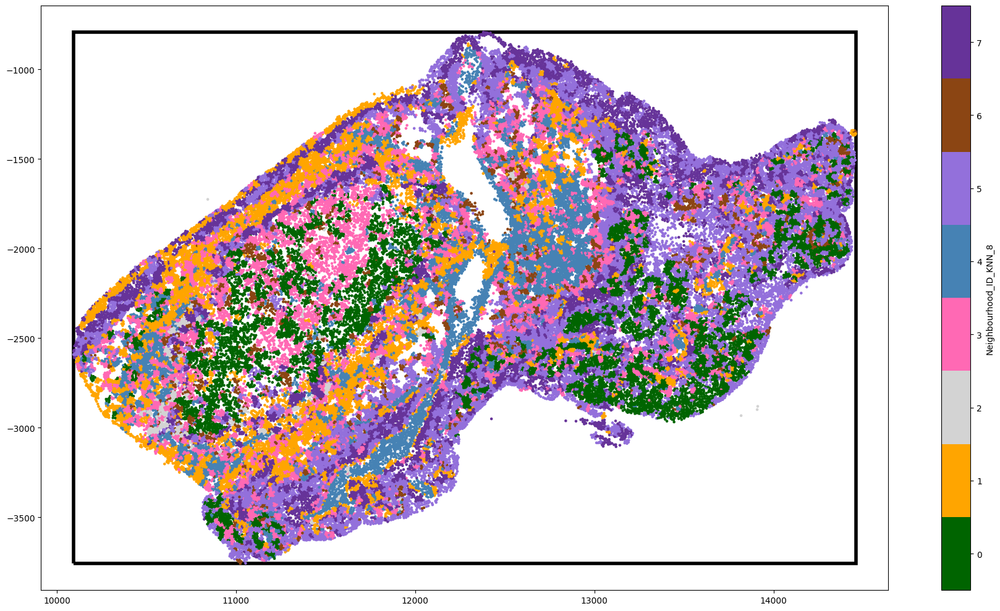

In [34]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Neighbourhood_ID_KNN_8',
                       show_boundary=True,
                       marker_size=5,
                       ax=ax)


"""
x_centre = 15000
y_centre = -22000
x_side = 600
y_side = 500

ax.set_xlim(x_centre - x_side, x_centre + x_side)
ax.set_ylim(y_centre - y_side, y_centre + y_side)

plt.savefig(os.path.join("D:\Muspan_temp\domains_for_example_images\Images","B22-906_ROI10.png"), transparent=None, dpi='figure', format='png',
        metadata=None, bbox_inches="tight", pad_inches=0,
        facecolor='auto', edgecolor='auto', backend=None)
"""

print(domain.name)

MP26_38_CR1_Scan1_muspan_1390304.csv


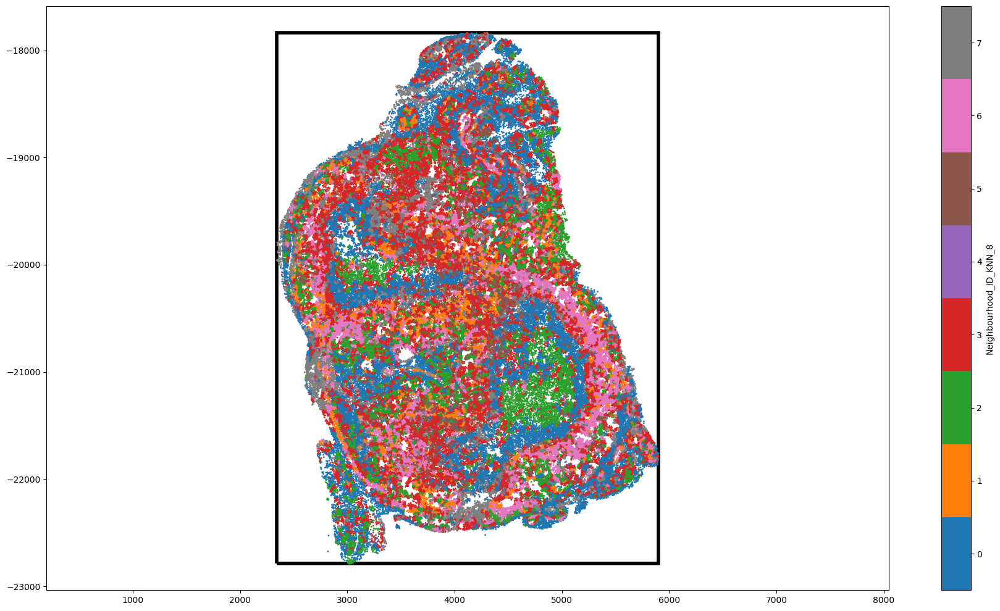

In [ ]:
domain8 = domain

fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain8,
                       color_by='Neighbourhood_ID_KNN_8',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390304.csv
Number of objects: 119765
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_9'] 
Networks: [] 
Distance matrices: []
MP26_38_CR1_Scan1_muspan_1390304.csv


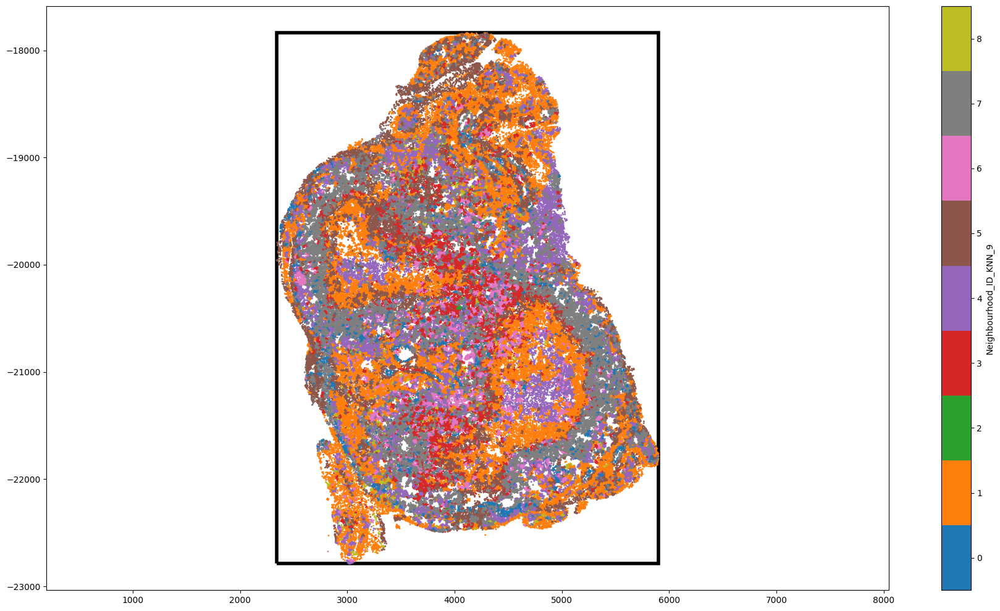

In [12]:
path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN9_ex139\domains\MP26_38_CR1_Scan1_muspan_1390304.csv.muspan"

domain9 = ms.io.load_domain(path)
fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain9,
                       color_by='Neighbourhood_ID_KNN_9',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390304.csv
Number of objects: 119765
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_10'] 
Networks: [] 
Distance matrices: []
MP26_38_CR1_Scan1_muspan_1390304.csv


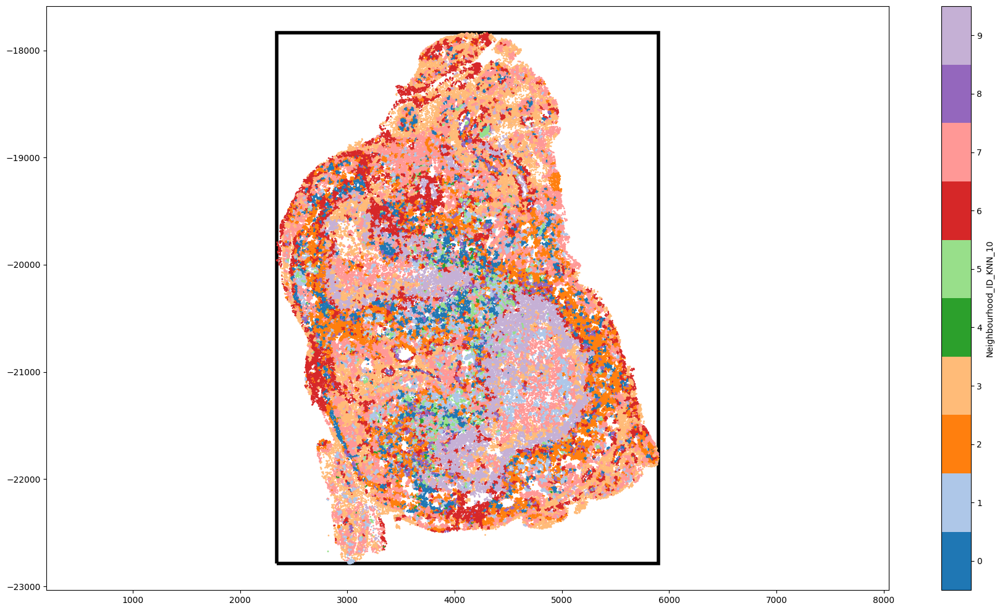

In [13]:
path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN10_ex139\domains\MP26_38_CR1_Scan1_muspan_1390304.csv.muspan"

domain10 = ms.io.load_domain(path)
fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain10,
                       color_by='Neighbourhood_ID_KNN_10',
                       show_boundary=True,
                       marker_size=1,
                       ax=ax)

print(domain.name)

In [2]:
import muspan as ms
import os

neighbourhood_colors = {
    0: 'darkgreen', 1: 'orange', 2: 'lightgray', 3: 'hotpink', 4: 'steelblue', 5: 'mediumpurple', 6: 'saddlebrown'}

path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains"
pbs_files = ["MP26_38_CR1_Scan1_muspan_1390102.csv.muspan", "MP26_38_CR1_Scan1_muspan_1390103.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390201.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390202.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390203.csv.muspan"]
IL12_files = ["MP26_38_CR1_Scan1_muspan_1390304.csv.muspan", "MP26_38_CR1_Scan1_muspan_1390301.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390402.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390403.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390302.csv.muspan"]
RT_files = ["MP26_38_CR1_Scan1_muspan_1390504.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390501.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390602.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390502.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390603.csv.muspan"]
RT_IL12_files = ["MP26_38_CR1_Scan1_muspan_1390701.csv.muspan", "MP26_38_CR2_Scan1(1)_muspan_1390703.csv.muspan", "MP26_38_CR3_Scan1_muspan_1390803.csv.muspan"]
EpCAM_PBS_files = ["MP26_38_CR4_Scan1_muspan_1391403.csv.muspan", "MP26_38_CR4_Scan1_muspan_1391302.csv.muspan", "MP26_38_CR4_Scan1_muspan_1391402.csv.muspan", "MP26_38_CR5_Scan1_muspan_1391401.csv.muspan", "MP26_38_CR5_Scan1_muspan_1391304.csv.muspan"]
EpCAM_IL12_files = ["MP26_38_CR4_Scan1_muspan_1391503.csv.muspan", "MP26_38_CR4_Scan1_muspan_1391502.csv.muspan", "MP26_38_CR4_Scan1_muspan_1391602.csv.muspan", "MP26_38_CR5_Scan1_muspan_1391603.csv.muspan", "MP26_38_CR5_Scan1_muspan_1391504.csv.muspan"]
NoDOX_files = ['MP26_38_CR5_Scan1_muspan_No DOX 48h.csv.muspan', 'MP26_38_CR5_Scan1_muspan_No dox-72h.csv.muspan']

UPP1_path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_66N_KNN8\domains"
UPP1_WT_files = ["MP26_38_CR6_Bottom_Scan1_muspan_66N0201.csv.muspan", "MP26_38_CR6_Bottom_Scan1_muspan_66N0203.csv.muspan", "MP26_38_CR6_Top_Scan1_muspan_66N0104.csv.muspan"]
UPP1_KO_files = ["MP26_38_CR6_Bottom_Scan1_muspan_66N0401.csv.muspan", "MP26_38_CR6_Bottom_Scan1_muspan_66N0301.csv.muspan", "MP26_38_CR6_Top_Scan1_muspan_66N0301.csv.muspan"]


Loading Domains
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390102.csv
Number of objects: 203738
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []
Domain MP26_38_CR1_Scan1_muspan_1390102.csv saved successfully to C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains.
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390103.csv
Number of objects: 160594
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []
Domain MP26_38_CR1_Scan1_muspan_1390103.csv saved successfully to C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains.
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR2_

ValueError: Unexpected filetype - expecting a .muspan domain

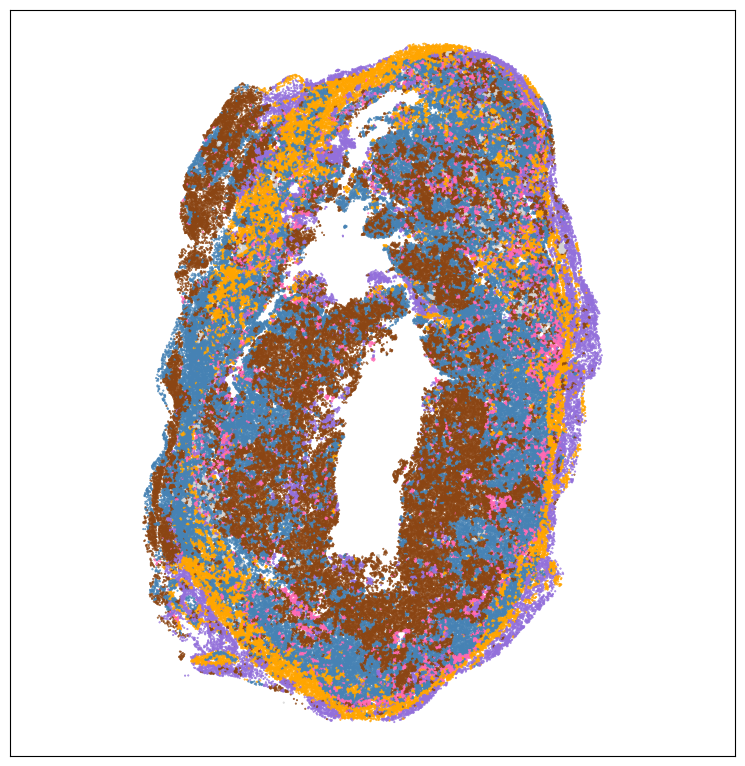

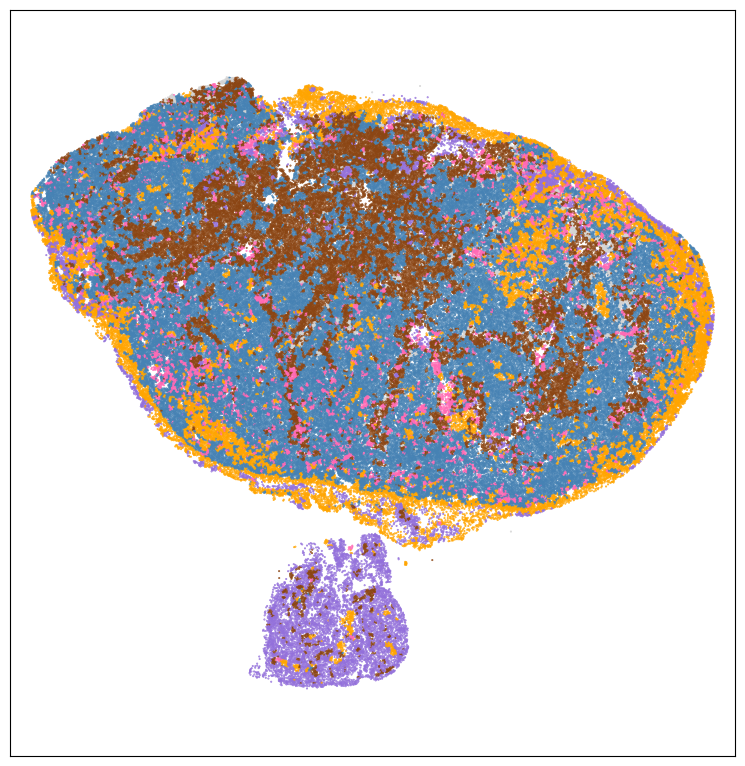

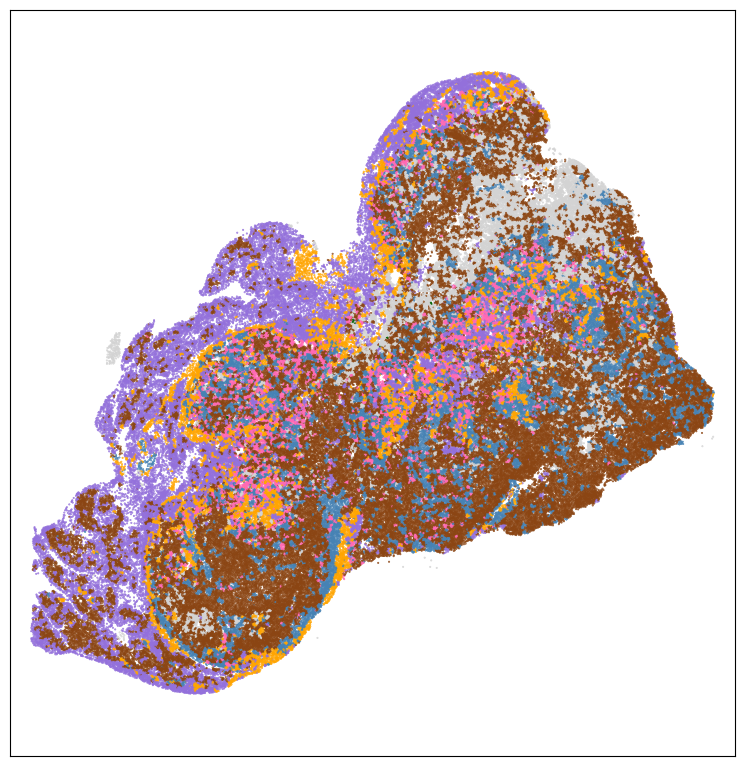

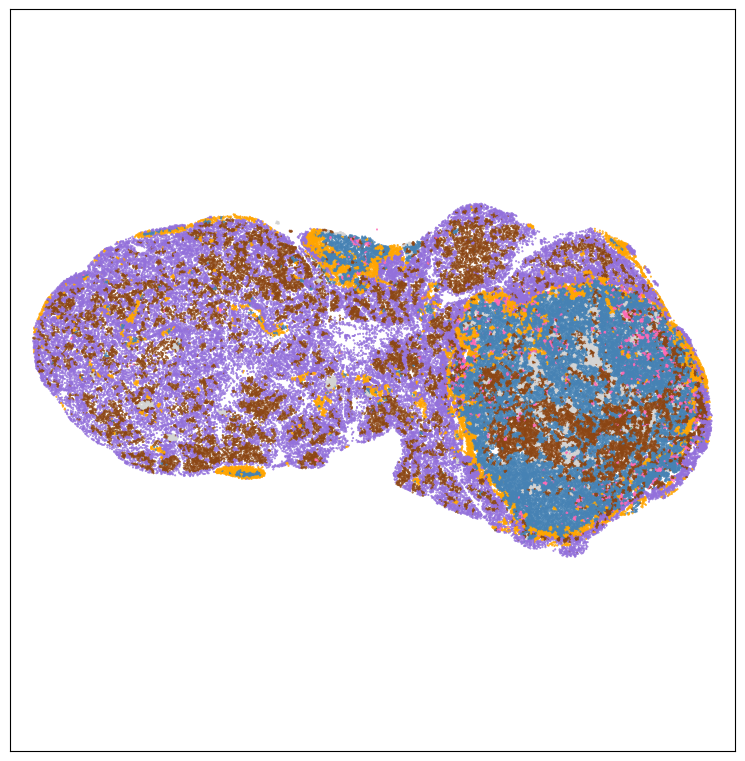

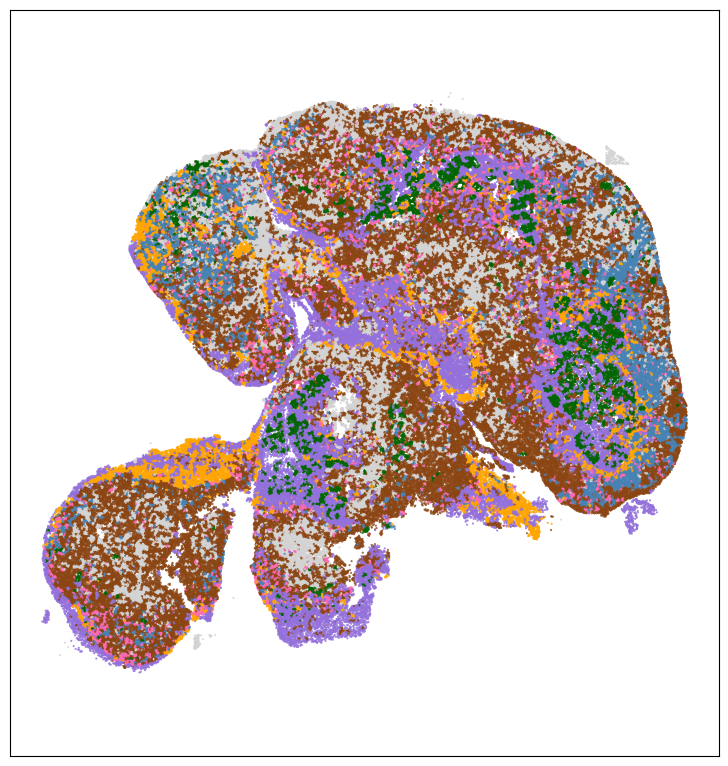

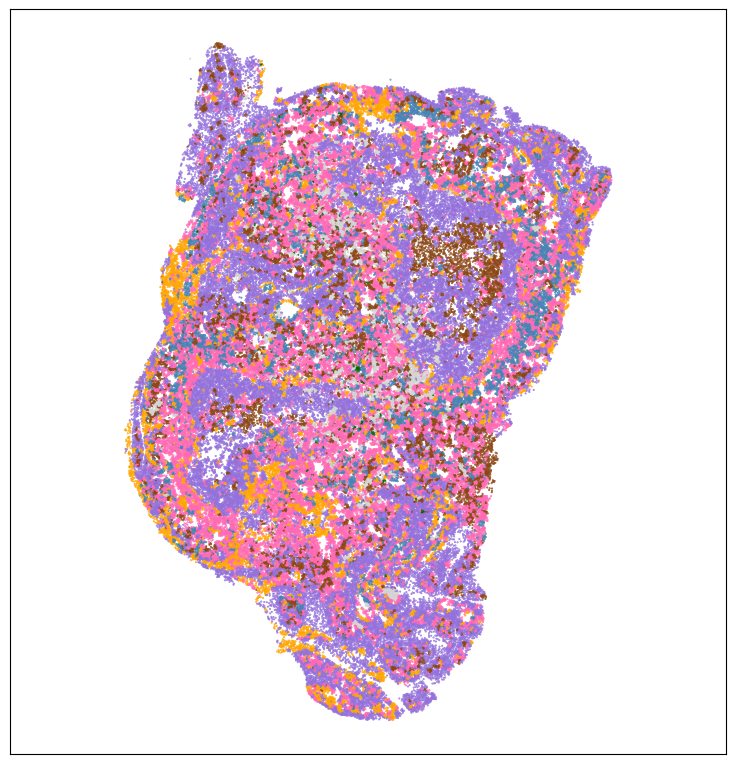

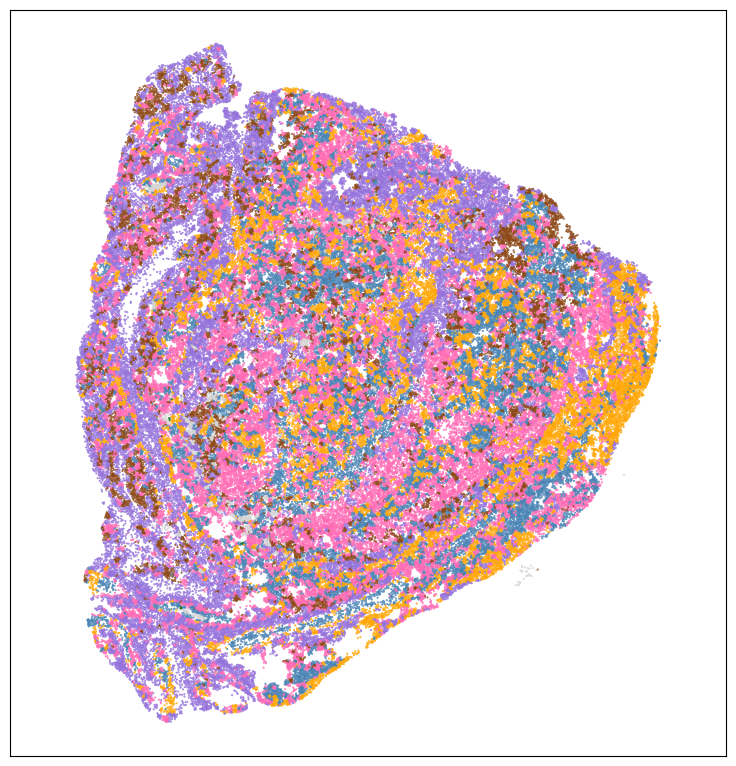

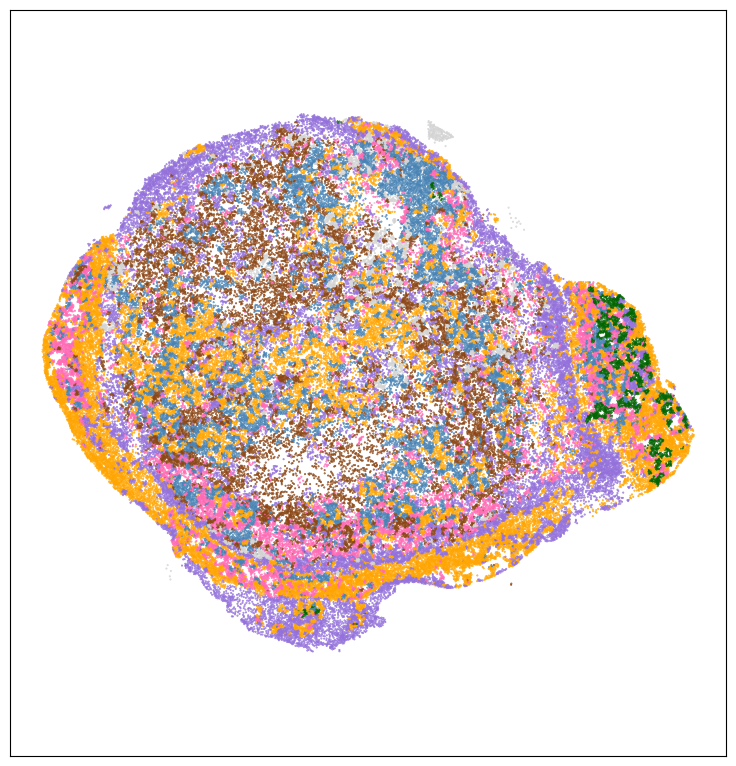

In [ ]:
import matplotlib.pyplot as plt

files = [pbs_files, IL12_files, RT_files, RT_IL12_files, EpCAM_PBS_files, EpCAM_IL12_files, NoDOX_files, UPP1_path, UPP1_WT_files, UPP1_KO_files]
names = ["PBS", "IL12", "RT", "RT_IL12", "EpCAM_PBS", "EpCAM_IL12", "NoDOX", "UPP1", "UPP1_WT", "UPP1_KO"]
i = 0
for file in files:
    domains = []

    print("Loading Domains")
    for sample in file:
        domain = ms.io.load_domain(os.path.join(path, sample))
        domain.update_colors(new_colors=neighbourhood_colors, colors_to_update="labels", label_name="Neighbourhood_ID_KNN_7")

        # Save domains again with updated colours
        ms.io.save_domain(domain, path_to_save=path, name_of_file= str(domain.name))
        
        domains.append(domain)

    output = os.path.join(r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\images", f"neighbourhood_{names[i]}")
    os.makedirs(output, exist_ok=True)
    i += 1

    for domain in domains:
        fig, ax = plt.subplots(figsize=(8, 8), ncols=1, nrows=1)


        ms.visualise.visualise(domain,
                        color_by='Neighbourhood_ID_KNN_7',
                        show_boundary=False,
                        marker_size=0.2,
                        ax=ax,
                        add_cbar=False)

        ax.set_xticks([])
        ax.set_yticks([])

        print(f"Saving image {domain.name}")
        plt.savefig(os.path.join(output, domain.name.replace(".csv", ".svg")), transparent=None, dpi='figure', format='svg',
            metadata=None, bbox_inches="tight", pad_inches=0,
            facecolor='auto', edgecolor='auto', backend=None)

MP26_38_CR4_Scan1_muspan_1391502.csv


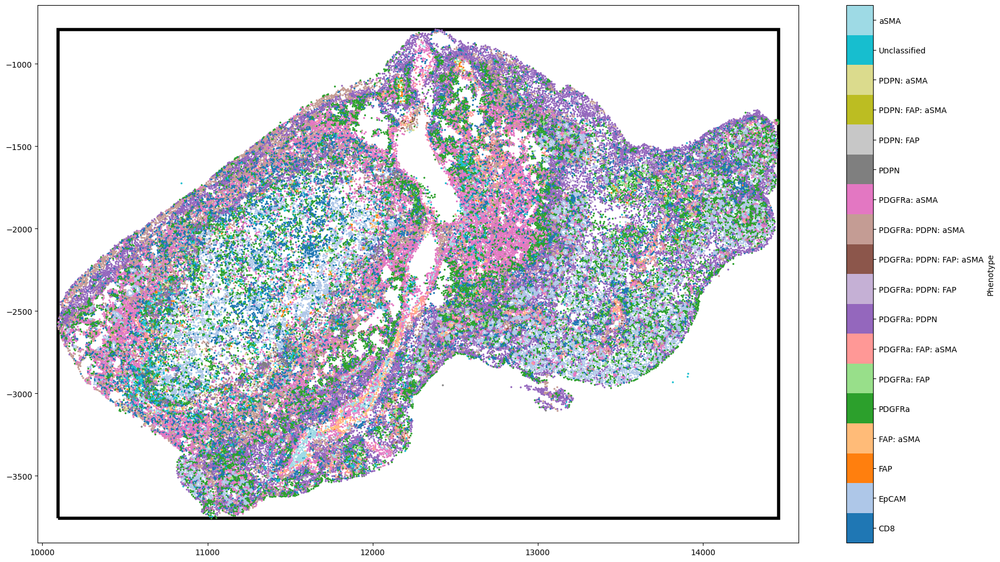

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Phenotype',
                       show_boundary=True,
                       marker_size=2,
                       ax=ax)


print(domain.name)

In [ ]:
# Plot colourbar separately
import matplotlib as mpl

fig, ax = plt.subplots(figsize=(10,8))
plt.rcParams['font.size'] = '20'
plt.rcParams['font.family'] = ['monospace'] #  {'cursive', 'fantasy', 'monospace', 'sans', 'sans serif', 'sans-serif', 'serif'}
ms.visualise.visualise(domain, ax=ax, color_by="Neighbourhood_ID_KNN_8", marker_size=1, add_cbar=True, cbar_kwargs={'location': 'bottom', #right, bottom
                                                                                                                           'orientation': 'horizontal', #vertical, horizontal
                                                                                                                           'label':'Cluster'})#,
                                                                                                                           #"cmap":colormaps["viridis"]})

ax.set_visible(False)